# Trabalho WMMA $2026$

In [1]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler


# Carrega os dados.
df = pd.read_csv('../database/processed/Dados_Arritmia_Renan.csv')

colunas_estatisticas = ["rr_pre", "rr_pos", "rr_pre_relativo", "rr_pos_relativo", 
                        "media_atual", "desvio_atual", "soma_quadratica_atual", 
                        "norma_atual", "rms_atual"]

colunas_estatisticas_semRR = [ "media_atual", "desvio_atual", "soma_quadratica_atual", 
                         "norma_atual", "rms_atual"]


label_mapping = {"F": -1, "N": 1, "S": -1, "V": -1, "Q": -1}
df['padrao_aami'] = df['padrao_aami'].map(label_mapping).astype(int)

# Separar teste e treino
df_treino = df[df['tipo'] == 'treino'].copy()
df_treino = df_treino[df_treino["padrao_aami"] == 1]
df_teste = df[df['tipo'] == 'teste'].copy()

# Diferentes cenários
# ------------ Estatísticas com RR ------------
X_treino_estatisticas = df_treino[colunas_estatisticas].copy()
X_teste_estatisticas = df_teste[colunas_estatisticas].copy()

scaler_estatisticas = MinMaxScaler()
X_treino_estatisticas = pd.DataFrame(
    scaler_estatisticas.fit_transform(X_treino_estatisticas),
    columns=colunas_estatisticas,
    index=X_treino_estatisticas.index,
)

X_teste_estatisticas = pd.DataFrame(
    scaler_estatisticas.transform(X_teste_estatisticas),
    columns=colunas_estatisticas,
    index=X_teste_estatisticas.index,
)

# ------------ Estatísticas sem RR ------------
X_treino_estatisticas_semRR = df_treino[colunas_estatisticas_semRR].copy()
X_teste_estatisticas_semRR = df_teste[colunas_estatisticas_semRR].copy()

scaler_estatisticas_semRR = MinMaxScaler()
scaler_estatisticas_semRR = MinMaxScaler()
X_treino_estatisticas_semRR = pd.DataFrame(
    scaler_estatisticas_semRR.fit_transform(X_treino_estatisticas_semRR),
    columns=colunas_estatisticas_semRR,
    index=X_treino_estatisticas_semRR.index,
)
X_teste_estatisticas_semRR = pd.DataFrame(
    scaler_estatisticas_semRR.transform(X_teste_estatisticas_semRR),
    columns=colunas_estatisticas_semRR,
    index=X_teste_estatisticas_semRR.index,
)


y_treino = df_treino['padrao_aami']
y_teste= df_teste['padrao_aami']

print('Dados Importados!')

Dados Importados!


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
)


def testar_modelo(y_test, y_pred, nome_modelo="Modelo", average="macro"):
    # Garante a conversão para array de inteiros mesmo se a entrada for lista
    y = np.asarray(y_test, dtype=int)
    y_p = np.asarray(y_pred, dtype=int)

    # Calculando as métricas de desempenho
    resultados = {
        "Modelo": nome_modelo,
        "Acurácia": accuracy_score(y, y_p) * 100,
        "Precisão": precision_score(y, y_p, average=average, zero_division=0) * 100,
        "Recall": recall_score(y, y_p, average=average, zero_division=0) * 100,
        "F1-Score": f1_score(y, y_p, average=average, zero_division=0) * 100,
        "MCC": matthews_corrcoef(y, y_p),
    }

    # Criação e formatação do DataFrame
    df_final = pd.DataFrame([resultados])

    print("\nRelatório de Desempenho:")
    print(
        df_final.to_string(
            index=False,
            formatters={
                "Acurácia": "{:,.2f}%".format,
                "Precisão": "{:,.2f}%".format,
                "Recall": "{:,.2f}%".format,
                "F1-Score": "{:,.2f}%".format,
                "MCC": "{:,.4f}".format,
            },
        )
    )

    # Invertido: 1 (Normal) primeiro, -1 (Anormal) depois
    classes = [1, -1]
    nomes_classes = ["Normal (1)", "Anormal (-1)"]

    # Plot da Matriz de Confusão
    fig, ax = plt.subplots(figsize=(6, 5))
    cm = confusion_matrix(y, y_p, labels=classes)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=nomes_classes
    )
    disp.plot(cmap=plt.cm.Blues, values_format="d", colorbar=False, ax=ax)
    
    ax.set_title(f"Matriz de Confusão - {nome_modelo.upper()}")
    plt.tight_layout()
    plt.show()

    return df_final

## Caso 1: Estatísticas sem RR's

In [3]:
from sklearn.ensemble import IsolationForest
from sklearn.inspection import permutation_importance
from sklearn.metrics import matthews_corrcoef, make_scorer

mcc_scorer = make_scorer(matthews_corrcoef)

isf_sem_rr = IsolationForest(random_state=14, n_jobs=-1)
isf_sem_rr.fit(X_treino_estatisticas_semRR)


resultado = permutation_importance(
    isf_sem_rr, X_teste_estatisticas_semRR, y_teste,
    n_repeats=100, random_state=14, scoring=mcc_scorer
)

for i, feature in enumerate(X_teste_estatisticas_semRR.columns):
    print(f"{feature}: {resultado.importances_mean[i]:.4f} +/- {resultado.importances_std[i]:.4f}")

media_atual: 0.0028 +/- 0.0022
desvio_atual: 0.0781 +/- 0.0025
soma_quadratica_atual: 0.0481 +/- 0.0024
norma_atual: 0.0484 +/- 0.0023
rms_atual: 0.0527 +/- 0.0024



Relatório de Desempenho:
              Modelo Acurácia Precisão Recall F1-Score    MCC
Estatisticas SEM RRs   78.50%   58.70% 70.64%   59.56% 0.2680


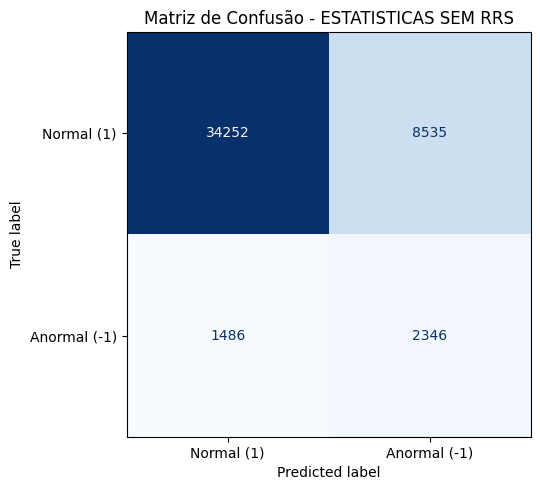

,Modelo,Acurácia,Precisão,Recall,F1-Score,MCC
0,Estatisticas SEM RRs,78.504472,58.70124,70.636823,59.564312,0.268004


In [4]:
y_pred_sem_rr = isf_sem_rr.predict(X_teste_estatisticas_semRR)

testar_modelo(y_teste, y_pred_sem_rr, 'Estatisticas SEM RRs')

## Caso 2: Estatísticas com RR's

In [5]:
mcc_scorer = make_scorer(matthews_corrcoef)

isf_com_rr = IsolationForest(random_state=14, n_jobs=-1)
isf_com_rr.fit(X_treino_estatisticas)


resultado = permutation_importance(
    isf_com_rr, X_teste_estatisticas, y_teste,
    n_repeats=100, random_state=14, scoring=mcc_scorer
)

for i, feature in enumerate(X_teste_estatisticas.columns):
    print(f"{feature}: {resultado.importances_mean[i]:.4f} +/- {resultado.importances_std[i]:.4f}")

rr_pre: 0.0064 +/- 0.0017
rr_pos: -0.0094 +/- 0.0022
rr_pre_relativo: 0.0352 +/- 0.0017
rr_pos_relativo: 0.0425 +/- 0.0022
media_atual: -0.0198 +/- 0.0020
desvio_atual: 0.0316 +/- 0.0015
soma_quadratica_atual: 0.0209 +/- 0.0017
norma_atual: 0.0079 +/- 0.0015
rms_atual: 0.0234 +/- 0.0017


## Resultados


Relatório de Desempenho:
              Modelo Acurácia Precisão Recall F1-Score    MCC
Estatisticas SEM RRs   78.50%   58.70% 70.64%   59.56% 0.2680


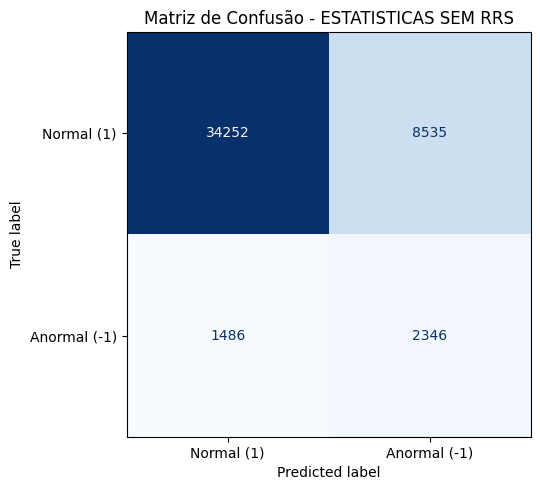


Relatório de Desempenho:
              Modelo Acurácia Precisão Recall F1-Score    MCC
Estatisticas COM RRs   79.06%   59.94% 73.94%   61.14% 0.3085


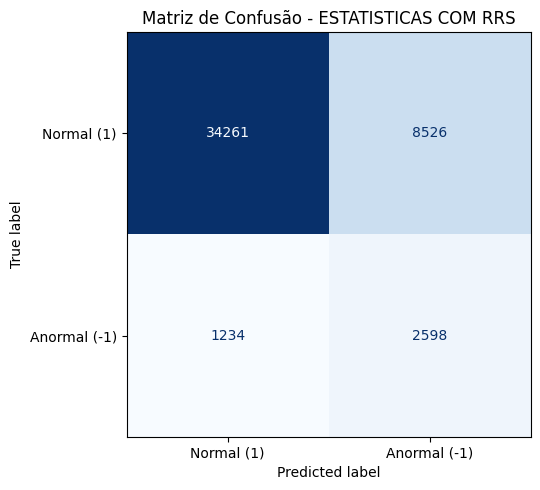

,Modelo,Acurácia,Precisão,Recall,F1-Score,MCC
0,Estatisticas COM RRs,79.06433,59.939181,73.935441,61.137082,0.308479


In [6]:
# Sem RR
y_pred_sem_rr = isf_sem_rr.predict(X_teste_estatisticas_semRR)
testar_modelo(y_teste, y_pred_sem_rr, 'Estatisticas SEM RRs')

# Com RR
y_pred_com_rr = isf_com_rr.predict(X_teste_estatisticas)
testar_modelo(y_teste, y_pred_com_rr, 'Estatisticas COM RRs')